# Chapter 15

Python version of the R code for Chapter 15 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly. R's `supsmu()` (Friedman's super smoother) has
no standard Python equivalent; the bootstrap likelihoods below are smoothed
with `lowess` instead.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
from statsmodels.nonparametric.smoothers_lowess import lowess

from helpers import scan, approx, meanlike

## Example 15.1, including Figure 15.1 (`EX15-1.R`)

3 -3.85 [0.43 0.37 0.09 0.07 0.03] -10.33
4 -0.85 [0.28 0.27 0.18 0.16 0.1 ] -8.4
4.9399999999999995 -0.0 [0.2 0.2 0.2 0.2 0.2] -8.05
6 0.52 [0.14 0.15 0.17 0.19 0.35] -8.34
7 0.97 [0.1  0.11 0.13 0.15 0.5 ] -9.08


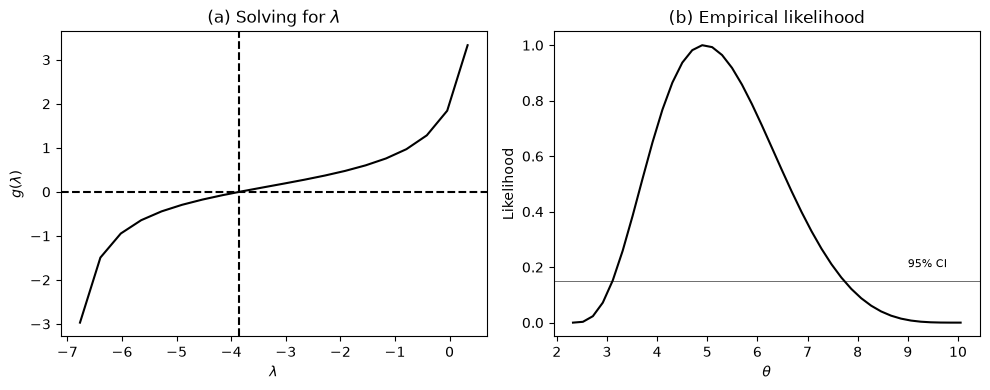

In [2]:
x = np.array([2.3, 2.4, 4.5, 5.4, 10.1])
n = len(x)


def glambda(t):
    """Grid of lambda and g(lambda) = sum (x-t)/(n - lambda (x-t))."""
    a = x - t
    lam = np.linspace(n / a.min(), n / a.max(), 22)[1:-1]
    glam = (a / (n - np.outer(lam, a))).sum(axis=1)
    return a, lam, glam


# trying a number of theta
th = [3, 4, x.mean(), 6, 7]
theta = []
loglik = []
for t in th:
    a, lam, glam = glambda(t)
    lam0 = approx(glam, lam, 0)
    if not np.isnan(lam0):  # lam0 exists
        w = 1 / (n - lam0 * a)
        ll = np.sum(np.log(w))
        print(t, round(lam0, 2), np.round(w, 2), round(ll, 2))
        theta.append(t)
        loglik.append(ll)

# Figure 15.1
# g-lambda
a, lam, glam = glambda(3)
lam0 = approx(glam, lam, 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(lam, glam, "k-")
ax.axhline(0, color="k", ls="--")
ax.axvline(lam0, color="k", ls="--")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$g(\lambda)$")
ax.set_title(r"(a) Solving for $\lambda$")

x = np.sort(x)  # be sure to use sorted x here
nt = 40
th = np.linspace(1.01 * x[0], x[n - 2] + .99 * (x[n - 1] - x[n - 2]), nt)

theta = []
loglik = []
for t in th:
    a, lam, glam = glambda(t)
    lam0 = approx(glam, lam, 0)
    if not np.isnan(lam0):  # lam0 exists
        w = 1 / (n - lam0 * a)
        theta.append(t)
        loglik.append(np.sum(np.log(w)))
theta = np.array(theta)
loglik = np.array(loglik)

lik = np.exp(loglik - loglik.max())
ax = axes[1]
ax.plot(theta, lik, "k-")
ax.axhline(0.15, color="k", lw=0.4)
ax.text(9, .2, "95% CI", fontsize=8)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(b) Empirical likelihood")
fig.tight_layout()
plt.show()

## Example 15.2 (`EX15-2.R`)

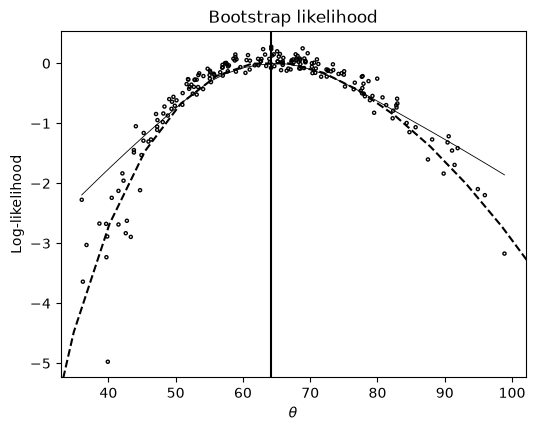

In [3]:
x = np.array([50, 44, 102, 72, 22, 39, 3, 15,
              197, 188, 79, 88, 46, 5, 5, 36,
              22, 139, 210, 97, 30, 23, 13, 14], dtype=float)
n = len(x)
tobs = x.mean()

bw = 5  # smoothing parameter to estimate h(theta, t_obs)
rng = np.random.default_rng(91)

nb = 200
M1 = []
lik = []
for i in range(nb):
    x1 = rng.choice(x, n)
    M1.append(x1.mean())
    x2 = rng.choice(x1, size=(nb, n))
    m2 = x2.mean(axis=1)
    # density estimate at t=tobs
    lik.append(np.sum(stats.norm.pdf(m2, loc=tobs, scale=bw)) / nb)
M1 = np.array(M1)
lik = np.array(lik)

# .................smoothing:
a = lowess(np.log(lik), M1)
ll = np.log(lik) - a[:, 1].max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(M1, ll, s=5, facecolors="none", edgecolors="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Log-likelihood")
ax.set_title("Bootstrap likelihood")
ll = a[:, 1] - a[:, 1].max()  # smoothed loglik
ax.plot(a[:, 0], ll, "k-", lw=0.6)
lims = ax.get_xlim(), ax.get_ylim()  # R fixes the axes from the first plot

# empirical likelihood for the mean
b_theta, b_loglik = meanlike(x)
ax.plot(b_theta, b_loglik, "k--")
ax.axvline(x.mean(), color="k")
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
plt.show()

## Example 15.3 (`EX15-3.R`)

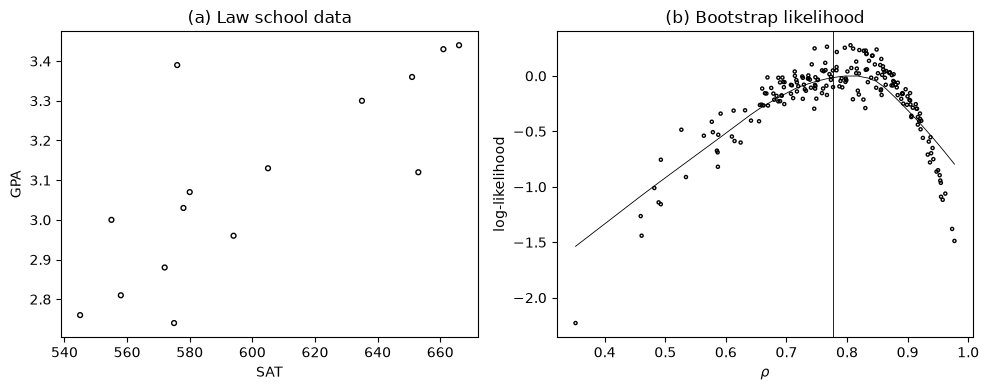

In [4]:
xdat = scan("law.dat").reshape(-1, 2)
x = xdat[:, 0]
y = xdat[:, 1]
n = len(x)
tobs = np.corrcoef(x, y)[0, 1]

bw = .1  # smoothing parameter to estimate h(theta, t_obs)
rng = np.random.default_rng(1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(x, y, s=12, facecolors="none", edgecolors="k")
ax.set_xlabel("SAT")
ax.set_ylabel("GPA")
ax.set_title("(a) Law school data")


def scale(m):
    """Standardise the columns of m, like R's scale()."""
    return (m - m.mean(axis=0)) / m.std(axis=0, ddof=1)


nb = 200
nb2 = 100
M1 = []
lik = []
for i in range(nb):
    idx = rng.integers(0, n, n)
    x1 = x[idx]
    y1 = y[idx]
    M1.append(np.corrcoef(x1, y1)[0, 1])
    id2 = rng.integers(0, n, size=(n, nb2))  # each column is a bootstrap sample
    x2 = x1[id2]
    y2 = y1[id2]
    cor2 = (scale(x2) * scale(y2)).sum(axis=0) / (n - 1)  # corrected version
    # density estimate at t=tobs
    lik.append(np.sum(stats.norm.pdf(cor2, loc=tobs, scale=bw)) / nb2)
M1 = np.array(M1)
lik = np.array(lik)

# smoothing:
a = lowess(np.log(lik), M1)
ll = np.log(lik) - a[:, 1].max()
ax = axes[1]
ax.scatter(M1, ll, s=5, facecolors="none", edgecolors="k")
ax.set_xlabel(r"$\rho$")
ax.set_ylabel("log-likelihood")
ax.set_title("(b) Bootstrap likelihood")
ll = a[:, 1] - a[:, 1].max()  # smoothed loglik
ax.plot(a[:, 0], ll, "k-", lw=0.6)
ax.axvline(tobs, color="k", lw=0.6)
fig.tight_layout()
plt.show()

## Example 15.4 (`EX15-4.R`)

Aircraft failure data.

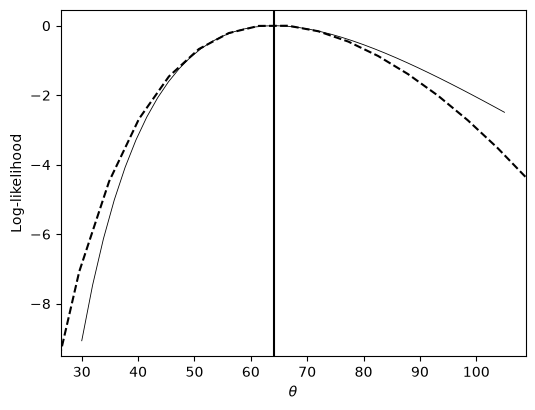

In [5]:
x = np.array([50, 44, 102, 72, 22, 39, 3, 15,
              197, 188, 79, 88, 46, 5, 5, 36,
              22, 139, 210, 97, 30, 23, 13, 14], dtype=float)
n = len(x)
tobs = x.mean()
x = np.sort(x)

# parametric likelihood
th = np.linspace(30, 105, 40)
ll = -n * np.log(th) - x.sum() / th
ll = ll - ll.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(th, ll, "k-", lw=0.6)
lims = ax.get_xlim(), ax.get_ylim()  # R fixes the axes from the first plot

# empirical likelihood
b_theta, b_loglik = meanlike(x)
ax.plot(b_theta, b_loglik, "k--")
ax.axvline(x.mean(), color="k")
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Log-likelihood")
plt.show()

## Example 15.5 (`EX15-5.R`)

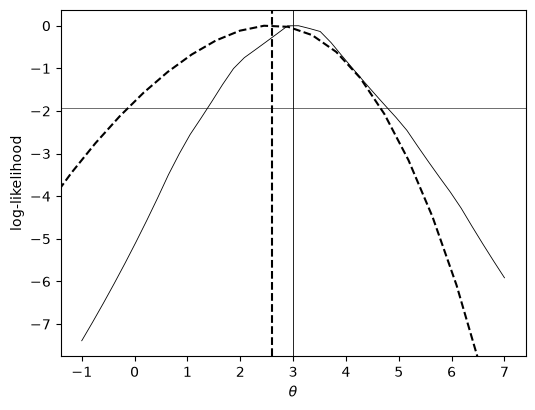

In [6]:
xdat = scan("darwin.dat").reshape(-1, 3)
x = xdat[:, 1] - xdat[:, 2]
sig = np.mean(np.abs(x - np.median(x)))  # scale estimate
n = len(x)
tobs = x.mean()
x = np.sort(x)

# parametric likelihood
th = np.linspace(-1, 7, 40)
ll = -n * np.log(np.abs(th[:, None] - x[None, :]).sum(axis=1))
ll = ll - ll.max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(th, ll, "k-", lw=0.6)
ax.axvline(np.median(x), color="k", lw=0.6)
lims = ax.get_xlim(), ax.get_ylim()  # R fixes the axes from the first plot

# empirical likelihood based on the mean
b_theta, b_loglik = meanlike(x)
ax.plot(b_theta, b_loglik, "k--")
ax.axvline(x.mean(), color="k", ls="--")
ax.axhline(-1.92, color="k", lw=0.4)
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("log-likelihood")
plt.show()

## Figure 15.4 (`FIG15-4.R`)

Empirical and BCa-bootstrap likelihood for the mean.

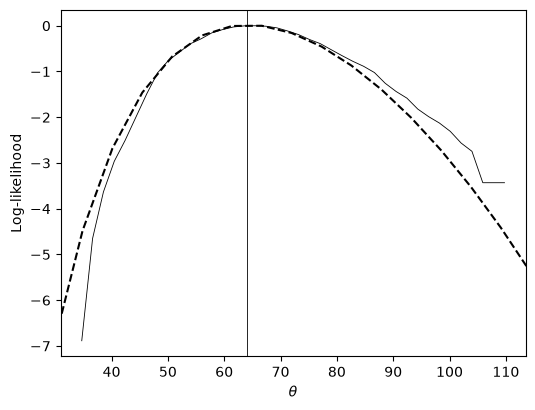

In [7]:
# aircraft failure data:
x = np.array([50, 44, 102, 72, 22, 39, 3, 15, 197, 188, 79, 88, 46, 5, 5,
              36, 22, 139, 210, 97, 30, 23, 13, 14], dtype=float)
n = len(x)

v0 = x.mean()
# bootstrap step:
nb = 1000
rng = np.random.default_rng(29)
xstar = rng.choice(x, size=(nb, n))
vstar = xstar.mean(axis=1)

# bootstrap
nt = 40
phi0 = stats.norm.ppf(np.sum(vstar < v0) / nb)
th = np.linspace(vstar.min() + 1, vstar.max() - 1, nt)
phi = np.array([stats.norm.ppf(np.sum(vstar < t) / nb) for t in th])

a = np.sum((x - x.mean()) ** 3) / 6 / np.sum((x - x.mean()) ** 2) ** 1.5
s = 1 + a * (phi - phi0)
pmean = -phi0 * s + phi
ln = stats.norm.pdf(phi0, loc=pmean, scale=s)  # .... BCa likelihood
bcall = np.log(ln) - np.log(ln).max()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(th, bcall, "k-", lw=0.6)
ax.axvline(x.mean(), color="k", lw=0.6)
lims = ax.get_xlim(), ax.get_ylim()  # R fixes the axes from the first plot

empll_theta, empll_loglik = meanlike(x)  # empirical likelihood
ax.plot(empll_theta, empll_loglik, "k--")
ax.set_xlim(lims[0])
ax.set_ylim(lims[1])
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Log-likelihood")
plt.show()

## Figure 15.5 (`FIG15-5.R`)

Profile likelihood for the correlation coefficient.

-0.13703895996114848 -0.07567156493787862


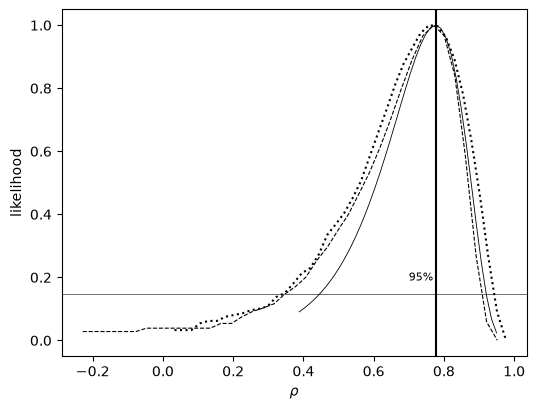

In [8]:
def pll(p, rho):
    """Minus log-likelihood of (mux, muy, sigx, sigy) at fixed rho."""
    mux, muy, sigx, sigy = p
    if sigx <= 0 or sigy <= 0:
        return np.inf
    c1 = sigx * sigy * np.sqrt(1 - rho ** 2)
    return ((n - 2) * np.log(c1)
            + 1 / 2 / (1 - rho ** 2) * (np.sum((x - mux) ** 2) / sigx ** 2
                                        - 2 * rho * np.sum((x - mux) * (y - muy)) / sigx / sigy
                                        + np.sum((y - muy) ** 2) / sigy ** 2))


xdat = scan("law.dat").reshape(-1, 2)
x = xdat[:, 0]
y = xdat[:, 1]
n = len(x)
rho_obs = np.corrcoef(x, y)[0, 1]

# computing profile likelihood numerically
nr = 40
rhopar = np.linspace(rho_obs / 2, .95, nr)
start = [x.mean(), y.mean(), np.std(x, ddof=1), np.std(y, ddof=1)]
ll0 = np.array([-optimize.minimize(pll, start, args=(rho,), method="Nelder-Mead",
                                   options={"maxiter": 4000}).fun
                for rho in rhopar])
lik12 = np.exp(ll0 - ll0.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(rhopar, lik12, "k-", lw=0.6)

rng = np.random.default_rng(1)
nb = 4000

mx = x.mean()
my = y.mean()
sx = np.std(x)  # divisor n
sy = np.std(y)

for ipar in [1, 2]:  # 1=parametric, 2=nonparametric
    if ipar == 1:
        xs = rng.normal(size=(nb, n)) * sx + mx
        ys = my + rho_obs * sy / sx * (xs - mx) + sy * np.sqrt(1 - rho_obs ** 2) * rng.normal(size=(nb, n))
    if ipar == 2:
        idx = rng.integers(0, n, size=(nb, n))
        xs = x[idx]
        ys = y[idx]
    xm = xs.mean(axis=1, keepdims=True)
    ym = ys.mean(axis=1, keepdims=True)

    covxy = ((xs - xm) * (ys - ym)).sum(axis=1)
    x2 = ((xs - xm) ** 2).sum(axis=1)
    y2 = ((ys - ym) ** 2).sum(axis=1)
    cor_b = covxy / np.sqrt(x2 * y2)  # bootstrap replications of cor

    # bootstrap likelihood
    rhoboot = np.linspace(cor_b.min() + .05, cor_b.max() - .02, nr)

    phi = np.array([stats.norm.ppf(np.sum(cor_b < r) / nb) for r in rhoboot])
    phi0 = stats.norm.ppf(np.sum(cor_b < rho_obs) / nb)

    # computing jackknife estimate of constant a
    # for correlation coef
    cori = np.array([np.corrcoef(np.delete(x, i), np.delete(y, i))[0, 1] for i in range(n)])
    mc = cori.mean()
    a = np.sum((mc - cori) ** 3) / 6 / np.sum((mc - cori) ** 2) ** (3 / 2)

    s = 1 + a * (phi - phi0)
    pmean = -phi0 * s + phi
    ln = stats.norm.pdf(phi0, loc=pmean, scale=s)
    lt = ln / np.nanmax(ln)

    if ipar == 1:
        ax.plot(rhoboot, lt, "k--", lw=0.8)
    if ipar == 2:
        ax.plot(rhoboot, lt, "k:", lw=1.5)

ax.axvline(rho_obs, color="k")
ax.axhline(np.exp(-1.96 ** 2 / 2), color="k", lw=0.4)
ax.text(.7, .19, "95%", fontsize=8)
ax.set_xlabel(r"$\rho$")
ax.set_ylabel("likelihood")
print(phi0, a)
plt.show()

## Figure 15.6 (`FIG15-6.R`)

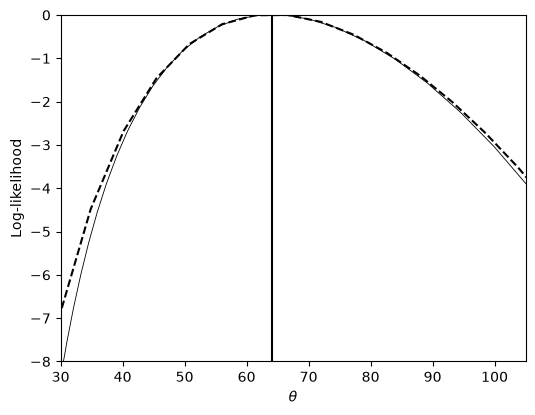

In [9]:
# aircraft failure data
x = np.array([50, 44, 102, 72, 22, 39, 3, 15,
              197, 188, 79, 88, 46, 5, 5, 36,
              22, 139, 210, 97, 30, 23, 13, 14], dtype=float)
n = len(x)

# lambda needs to be chosen so that theta covers enough of the
# parameter space around xbar
lam = np.linspace(-.05, .05, 100)
elx = np.exp(np.outer(lam, x))
theta = (x * elx).sum(axis=1)
sumexp = elx.sum(axis=1)
theta = theta / sumexp
Ka = np.log(sumexp / n)
sadll = n * lam * x.mean() - n * Ka  # alternative likelihood

# direct computation of likelihood:
dirll = lam * x.sum() - n * np.log(sumexp)
dirll = dirll - dirll.max()  # should be the same as sadll

a_theta, a_loglik = meanlike(x)  # empirical likelihood
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, dirll, "k-", lw=0.6)  # saddlepoint approximation
ax.plot(a_theta, a_loglik, "k--")
ax.axvline(x.mean(), color="k")
ax.set_xlim(30, 105)
ax.set_ylim(-8, 0)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Log-likelihood")
plt.show()